```{index} disjunctive programming
```
```{index} single: solver; HiGHS
```
```{index} single: application; maintenance planning
```

# Extra material: Maintenance planning

## Problem statement

A process unit is operating over a maintenance planning horizon from $1$ to $T$ days.  On day $t$ the unit makes a profit $c_t$ which is known in advance. The unit needs to shut down for $P$ maintenance periods during the planning period.  Once started, a maintenance period takes $M$ days to finish.

Find a maintenance schedule that allows the maximum profit to be produced.

## Preamble: Install Pyomo and a solver

The following cell sets and verifies a global SOLVER for the notebook. If run on Google Colab, the cell installs Pyomo and the HiGHS solver, while, if run elsewhere, it assumes Pyomo and HiGHS have been previously installed. It then sets to use HiGHS as solver via the appsi module and a test is performed to verify that it is available. The solver interface is stored in a global object `SOLVER` for later use.

In [1]:
import sys
 
if 'google.colab' in sys.modules:
    %pip install pyomo >/dev/null 2>/dev/null
    %pip install highspy >/dev/null 2>/dev/null
 
solver = 'appsi_highs'

import pyomo.environ as pyo
SOLVER = pyo.SolverFactory(solver)
 
assert SOLVER.available(), f"Solver {solver} is not available."

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyomo.gdp as gdp

## Modeling with disjunctive constraints

The model uses binary variables $x_t$ for days $t=1,\ldots,T$, with $x_t=1$ indicating that the unit operates and earns profit $c_t$. A maintenance start must leave time for all $M$ shutdown days within the horizon, so its possible dates are $Y=\{1,\ldots,T-M+1\}$. For $t\in Y$, the binary variable $y_t=1$ indicates the first day of a maintenance period.


### Objective

The planning objective is to maximize profit realized over the $T$-day planning horizon. This is achieved by maximizing the sum of the products of the profit per day $c_t$ and the binary variable $x_t$ indicating the unit is operating on that day.

$$
\begin{align*}
\text{Profit} & = \sum_{t=1}^T c_t x_t
\end{align*}
$$

### Constraints

**Number of maintenance periods is equal to P.**

Completing $P$ maintenance periods requires a total of $P$ starts.

$$
\sum_{t\in Y} y_t=P.
$$

**Maintenance periods do not overlap.**

No more than one maintenance period can start in any consecutive set of $M$ days. Only possible start dates in $Y$ are included in the sum:

$$
\sum_{\substack{0\leq s<M\\t+s\in Y}} y_{t+s}\leq1
\qquad \forall t\in Y.
$$

This requirement can be strengthened if a gap is needed between maintenance periods.

**The unit must shut down for M days following a maintenance start.**

If $y_t=1$, the operating level must be zero on days $t,\ldots,t+M-1$. Equivalently, either there is no start on day $t$, or all $M$ operating levels are zero:

$$
\left(y_t=0\right)\ \lor\
\left(\sum_{s=0}^{M-1}x_{t+s}=0\right)
\qquad \forall t\in Y.
$$

The two algebraic conditions can both hold: a day with no maintenance start may still fall within an existing shutdown. In Pyomo, `xor=True` selects exactly one disjunct to enforce; it does not require the algebraic conditions in the unselected disjunct to be false.


## Pyomo implementation

### Pyomo model

The disjunctive constraints can be represented directly using Pyomo's [Generalized Disjunctive Programming](https://pyomo.readthedocs.io/en/stable/explanation/modeling/gdp/modeling.html) extension. The following model uses the hull reformulation, `gdp.hull`, to obtain a mixed integer linear optimization (MILO) problem.


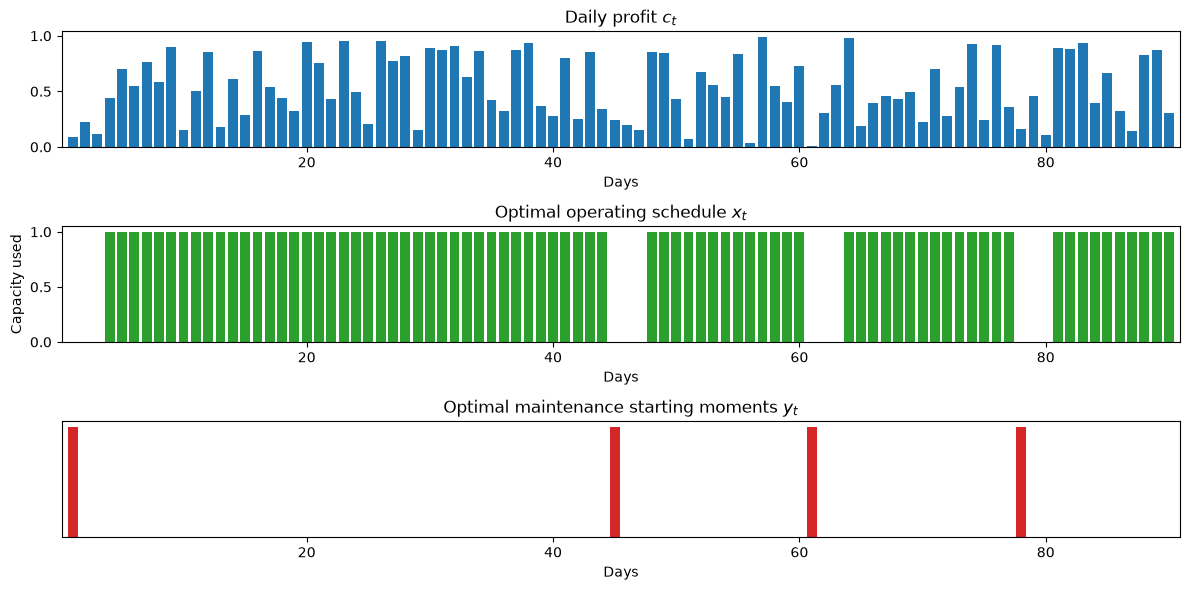

In [3]:
def maintenance_planning(c, M, P):
    m = pyo.ConcreteModel("Maintenance planning")

    T = len(c)
    m.T = pyo.RangeSet(1, T)
    m.Y = pyo.RangeSet(1, T - M + 1)
    m.S = pyo.RangeSet(0, M - 1)

    m.c = pyo.Param(m.T, initialize=c)
    m.x = pyo.Var(m.T, domain=pyo.Binary)
    m.y = pyo.Var(m.Y, domain=pyo.Binary)

    @m.Objective(sense=pyo.maximize)
    def profit(m):
        return sum(m.c[t] * m.x[t] for t in m.T)

    @m.Constraint()
    def required_maintenance(m):
        return P == sum(m.y[t] for t in m.Y)

    @m.Constraint(m.Y)
    def no_overlap(m, t):
        return sum(m.y[t + s] for s in m.S if t + s in m.Y) <= 1

    @m.Disjunction(m.Y, xor=True)
    def required_shutdown(m, t):
        return [[m.y[t] == 0], [sum(m.x[t + s] for s in m.S) == 0]]

    pyo.TransformationFactory("gdp.hull").apply_to(m)

    results = SOLVER.solve(m)
    pyo.assert_optimal_termination(results)

    return m


def plot_schedule(m):
    tab20 = plt.get_cmap("tab20", 20)
    colors = [tab20(i) for i in [0, 2, 4, 6]]

    fig, ax = plt.subplots(3, 1, figsize=(12, 6))

    ax[0].bar(m.T, [m.c[t] for t in m.T], color=colors[0])
    ax[0].set_title("Daily profit $c_t$")

    ax[1].bar(m.T, [m.x[t]() for t in m.T], color=colors[2])
    ax[1].set_title("Optimal operating schedule $x_t$")
    ax[1].set_ylabel("Capacity used")

    ax[2].bar(m.Y, [m.y[t]() for t in m.Y], color=colors[3])
    ax[2].set_title("Optimal maintenance starting moments $y_t$")
    ax[2].yaxis.set_ticks([])
    ax[2].yaxis.set_ticklabels([])

    for a in ax:
        a.set_xlim(0.1, len(m.T) + 0.9)
        a.set_xlabel("Days")

    plt.tight_layout()


# setting problem parameters
T = 90  # planning horizon
M = 3  # length of maintenance period
P = 4  # number of maintenance periods

# create a random number generator
rng = np.random.default_rng(2023)

# use the random number generator to generate random daily profits
c = {k: rng.uniform() for k in range(1, T + 1)}

model = maintenance_planning(c, M, P)
plot_schedule(model)

## Ramping constraints

Prior to maintenance shutdown, a large processing unit may take some time to safely ramp down from full production. Furthermore, it also requires more time to safely ramp back up to full production after maintenance. To account for ramp-down and ramp-up periods, we modify the problem formulation in the following ways.

* The variable denoting unit operation, $x_t$ is changed from a binary variable to a continuous variable $0 \leq x_t \leq 1$ denoting the fraction of total capacity at which the unit is operating on day $t$.

* Two new variable sequences, $0 \leq u_t^+ \leq u_t^{+,\max}$ and $0\leq u_t^- \leq u_t^{-,\max}$, are introduced which denote the fractional increase or decrease in unit capacity completed on day $t$.

* An additional sequence of equality constraints is introduced relating $x_t$ to $u_t^+$ and $u_t^-$:

$$
\begin{align*}
x_{t} & = x_{t-1} + u^+_t - u^-_t \quad \forall \, t = 2, 3, \ldots, T.
\end{align*}
$$

The next model adds these ramping constraints to the same shutdown disjunctions and again uses the hull reformulation.

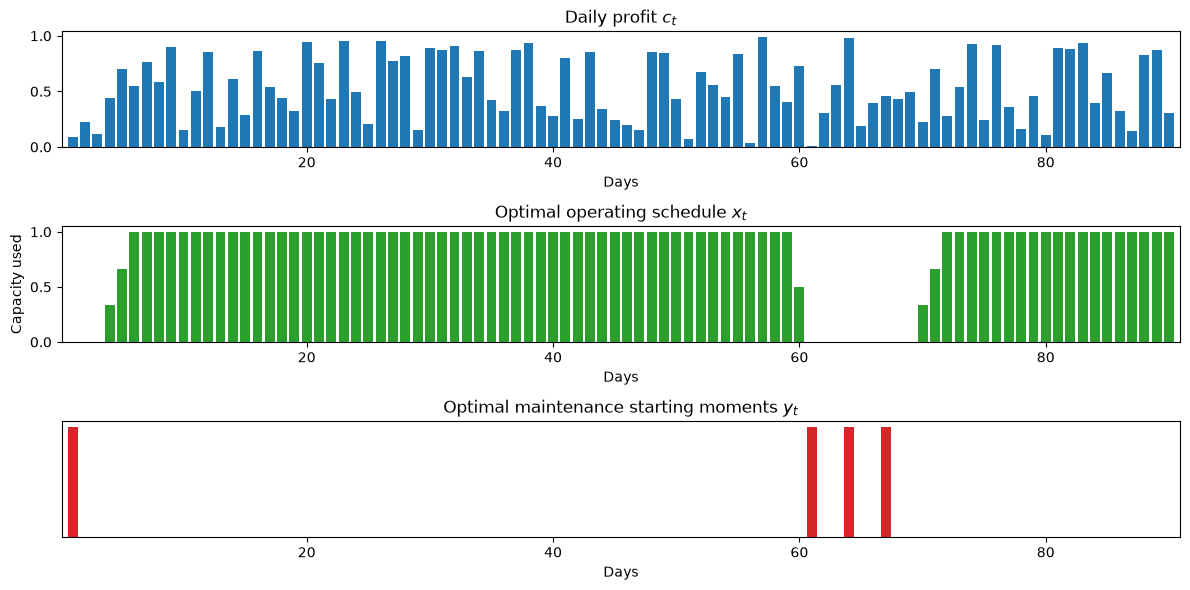

In [4]:
# Parameters for ramping constraints
upos_max = 0.3334
uneg_max = 0.5000


def maintenance_planning_ramp(c, M, P):
    m = pyo.ConcreteModel("Maintenance planning with ramping constraints")

    T = len(c)
    m.T = pyo.RangeSet(1, T)
    m.Y = pyo.RangeSet(1, T - M + 1)
    m.S = pyo.RangeSet(0, M - 1)

    m.c = pyo.Param(m.T, initialize=c)
    m.x = pyo.Var(m.T, bounds=(0, 1))
    m.y = pyo.Var(m.Y, domain=pyo.Binary)
    m.upos = pyo.Var(m.T, bounds=(0, upos_max))
    m.uneg = pyo.Var(m.T, bounds=(0, uneg_max))

    @m.Objective(sense=pyo.maximize)
    def profit(m):
        return sum(m.c[t] * m.x[t] for t in m.T)

    @m.Constraint()
    def required_maintenance(m):
        return P == sum(m.y[t] for t in m.Y)

    @m.Constraint(m.Y)
    def no_overlap(m, t):
        return sum(m.y[t + s] for s in m.S if t + s in m.Y) <= 1

    @m.Disjunction(m.Y, xor=True)
    def required_shutdown(m, t):
        return [[m.y[t] == 0], [sum(m.x[t + s] for s in m.S) == 0]]

    @m.Constraint(m.T)
    def ramp(m, t):
        if t == 1:
            return pyo.Constraint.Skip
        else:
            return m.x[t] == m.x[t - 1] + m.upos[t] - m.uneg[t]

    pyo.TransformationFactory("gdp.hull").apply_to(m)

    results = SOLVER.solve(m)
    pyo.assert_optimal_termination(results)

    return m


m = maintenance_planning_ramp(c, M, P)
plot_schedule(m)

## Spacing between maintenance periods

Without an additional gap, maintenance periods can be scheduled back-to-back. We now require at least $N$ days outside maintenance between successive maintenance periods. These days can include ramping: the requirement spaces the maintenance starts, rather than imposing positive or full-capacity production on each intervening day.

If one period starts on day $t$, the next can start no earlier than day $t+M+N$. Thus the start-spacing constraint is

$$
\sum_{\substack{0\leq s<M+N\\t+s\in Y}} y_{t+s}\leq1
\qquad \forall t\in Y.
$$

The shutdown still lasts $M$ days, so its disjunction is unchanged:

$$
\left(y_t=0\right)\ \lor\
\left(\sum_{s=0}^{M-1}x_{t+s}=0\right)
\qquad \forall t\in Y.
$$

An equivalent direct big-M constraint is

$$
\sum_{s=0}^{M-1}x_{t+s}\leq M(1-y_t)
\qquad \forall t\in Y.
$$

The bound $0\leq x_t\leq1$ makes $M$ a valid big-M coefficient for this sum of $M$ terms. A final maintenance period may finish on day $T$; no additional gap after that last period is imposed outside the planning horizon.

The following cell uses the direct big-M constraint. The commented GDP alternative enforces the same $M$-day shutdown; use one shutdown block or the other, with the common start-spacing constraint.


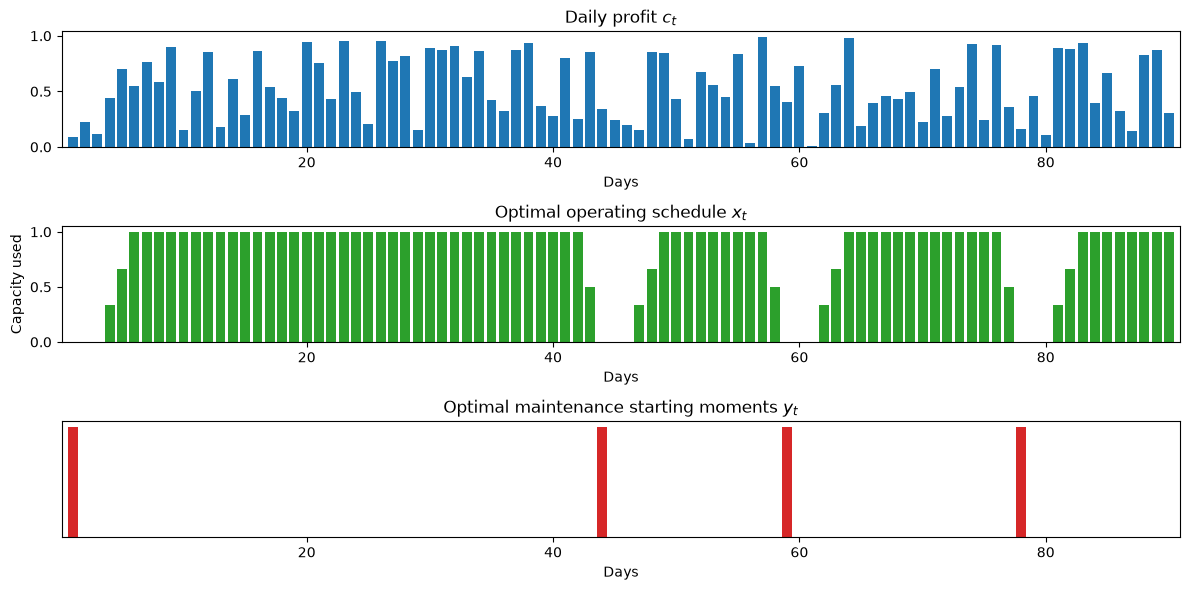

In [5]:
# Set the minimum gap between successive maintenance periods
N = 10


def maintenance_planning_ramp_operational(c, T, M, P, N):
    m = pyo.ConcreteModel(
        "Maintenance planning with ramping constraints and minimum maintenance gap"
    )

    m.T = pyo.RangeSet(1, T)
    m.Y = pyo.RangeSet(1, T - M + 1)
    m.S = pyo.RangeSet(0, M - 1)
    m.W = pyo.RangeSet(0, M + N - 1)

    m.c = pyo.Param(m.T, initialize=c)
    m.x = pyo.Var(m.T, bounds=(0, 1))
    m.y = pyo.Var(m.Y, domain=pyo.Binary)
    m.upos = pyo.Var(m.T, bounds=(0, upos_max))
    m.uneg = pyo.Var(m.T, bounds=(0, uneg_max))

    @m.Objective(sense=pyo.maximize)
    def profit(m):
        return sum(m.c[t] * m.x[t] for t in m.T)

    # ramp constraint
    @m.Constraint(m.T)
    def ramp(m, t):
        if t > 1:
            return m.x[t] == m.x[t - 1] + m.upos[t] - m.uneg[t]
        return pyo.Constraint.Skip

    # required number P of maintenance starts
    @m.Constraint()
    def sumy(m):
        return sum(m.y[t] for t in m.Y) == P

    # no more than one maintenance start in a window of length M + N
    @m.Constraint(m.Y)
    def sprd(m, t):
        return sum(m.y[t + s] for s in m.W if t + s in m.Y) <= 1

    # GDP alternative: use this block instead of the direct big-M block below.
    # @m.Disjunction(m.Y, xor=True)
    # def disj(m, t):
    #     return [[m.y[t] == 0], [sum(m.x[t + s] for s in m.S) == 0]]
    # pyo.TransformationFactory("gdp.bigm").apply_to(m)

    # Direct big-M shutdown: M days, independently of the spacing N.
    @m.Constraint(m.Y)
    def bigm(m, t):
        return sum(m.x[t + s] for s in m.S) <= M * (1 - m.y[t])

    results = SOLVER.solve(m)
    pyo.assert_optimal_termination(results)

    return m


m = maintenance_planning_ramp_operational(c, T, M, P, N)
plot_schedule(m)

## Exercises

1. Rather than specify how many maintenance periods must be accommodated, modify the model so that the process unit can operate no more than $L$ days without a maintenance shutdown.  (Hint. You may need to introduce an additional set of binary variables, $z_t$ to denote the start of an operational period.)

2. Do a systematic comparison of the Big-M, Convex Hull, and Cutting Plane techniques for implementing the disjunctive constraints. Your comparison should include a measure of complexity (such as the number of decision variables and constraints in the resulting transformed problems), computational effort, and the effect of solver choice (such as HiGHS vs cbc).